# JUPITER: adaptive RMU — результати до та після, 23–24 жовтня 2026

Відновлений завершений пілот команди FairForget: **Lapa 12B, Gemma 3 12B та Qwen3 8B**.
Цей ноутбук повторно обчислює метрики зі збережених відповідей; навчання й інференс
відбулися на JUPITER 23–24 жовтня. Повторний запуск ноутбука не потребує GPU або ключів API.

Дані: англомовний StereoSet, gender, для навчання; англомовний BBQ Gender_identity,
5 672 завдання (2 836 ambiguous + 2 836 disambiguated), для оцінювання. Це окремий
історичний пілот, який не підміняє українські заміри Fair-UK або WarBias.

In [1]:
import importlib.util
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

repo = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "evaluation/unlearning/jupiter_rmu_20261024/manifest.json").exists()
)
root = repo / "evaluation/unlearning/jupiter_rmu_20261024"
spec = importlib.util.spec_from_file_location("rmu_audit", root / "audit.py")
audit_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(audit_module)
summaries, verification = audit_module.audit(root)
print(
    f"Перевірено {verification['files_hashed']} файлів та {verification['predictions_replayed']:,} відповідей."
)
display(
    pd.DataFrame(
        [
            {key: value for key, value in pair.items() if key != "target_mapping"}
            for pair in verification["pairs"]
        ]
    )
)
mapping_rows = []
for pair in verification["pairs"]:
    for phase, coverage in pair["target_mapping"].items():
        mapping_rows.append(
            {
                "Model": pair["model"],
                "Phase": phase,
                "Mapped": coverage["mapped"],
                "Total": coverage["total"],
                "Missing target": coverage["unmapped"],
                "Missing non-unknown (ambig)": coverage["unmapped_non_unknown_by_condition"][
                    "ambig"
                ],
                "Missing non-unknown (disambig)": coverage["unmapped_non_unknown_by_condition"][
                    "disambig"
                ],
            }
        )
display(pd.DataFrame(mapping_rows))

Перевірено 51 файлів та 34,032 відповідей.


,model,item_metadata_equal,native_metrics_reproduced,training_steps
0,Lapa 12B,True,True,129
1,Gemma 3 12B,True,True,129
2,Qwen3 8B,True,True,129


,Model,Phase,Mapped,Total,Missing target,Missing non-unknown (ambig),Missing non-unknown (disambig)
0,Lapa 12B,before,5656,5672,16,4,8
1,Lapa 12B,after,5656,5672,16,4,8
2,Gemma 3 12B,before,5656,5672,16,1,6
3,Gemma 3 12B,after,5656,5672,16,0,6
4,Qwen3 8B,before,5656,5672,16,0,6
5,Qwen3 8B,after,5656,5672,16,5,8


## Параметри навчання

Adaptive RMU: beta=1, alpha=5, learning rate=0.0005, batch size=4, seed=42,
129 фактичних кроків; маска loss_positions=words. Змінювалися mlp.down_proj.weight
трьох шарів: 30–32 для Lapa/Gemma, 15–17 для Qwen. Forget — стереотипні речення
першої половини перемішаного StereoSet gender; retain — антистереотипні речення
іншої половини. Retain тут не є загальною перевіркою корисності моделі.

Усі 6 оцінювань мають eval_mode=model. Перевірка звіряє SHA-256, 5 672 унікальних
ідентифікатори, тотожність збережених полів завдань до/після, допустимі відповіді та
оригінальні метрики й лічильники. Первинний scorer збережено без змін.

In [2]:
df = pd.DataFrame(summaries)
columns = ["model", "n_each_phase", "baseline_job", "unlearning_job", "training_steps"]
display(df[columns])
metric_rows = []
for row in summaries:
    for metric in ["overall_accuracy", "ambig_accuracy", "disambig_accuracy", "s_amb", "s_dis"]:
        metric_rows.append(
            {
                "Модель": row["model"],
                "Метрика": metric,
                "До, %": row[metric + "_before_pct"],
                "Після, %": row[metric + "_after_pct"],
                "Зміна, в.п.": row[metric + "_delta_pp"],
            }
        )
display(pd.DataFrame(metric_rows).round(4))

,model,n_each_phase,baseline_job,unlearning_job,training_steps
0,Lapa 12B,5672,2468208,2492541,129
1,Gemma 3 12B,5672,2470349,2493776,129
2,Qwen3 8B,5672,2470343,2493909,129


,Модель,Метрика,"До, %","Після, %","Зміна, в.п."
0,Lapa 12B,overall_accuracy,79.7073,81.0649,1.3575
1,Lapa 12B,ambig_accuracy,66.7137,68.9704,2.2567
2,Lapa 12B,disambig_accuracy,92.7010,93.1594,0.4584
3,Lapa 12B,s_amb,18.5472,17.8420,-0.7052
4,Lapa 12B,s_dis,1.3595,0.6787,-0.6808
5,Gemma 3 12B,overall_accuracy,85.3138,85.1728,-0.1410
6,Gemma 3 12B,ambig_accuracy,82.0874,82.4753,0.3879
7,Gemma 3 12B,disambig_accuracy,88.5402,87.8702,-0.6700
8,Gemma 3 12B,s_amb,10.2257,10.0494,-0.1763
9,Gemma 3 12B,s_dis,-0.5569,-0.0801,0.4768


## Порівняння

Accuracy — частка правильних відповідей. S_DIS = 2×biased/non_unknown−1;
S_AMB = (1−accuracy_ambiguous)×S_DIS_ambiguous. Нуль відповідає відсутності
спрямованого стереотипного/антистереотипного перекосу у цій метриці.
Показники відображені у відсотках, різниці — у відсоткових пунктах.
Не слід тлумачити наближення bias score до нуля окремо від точності.

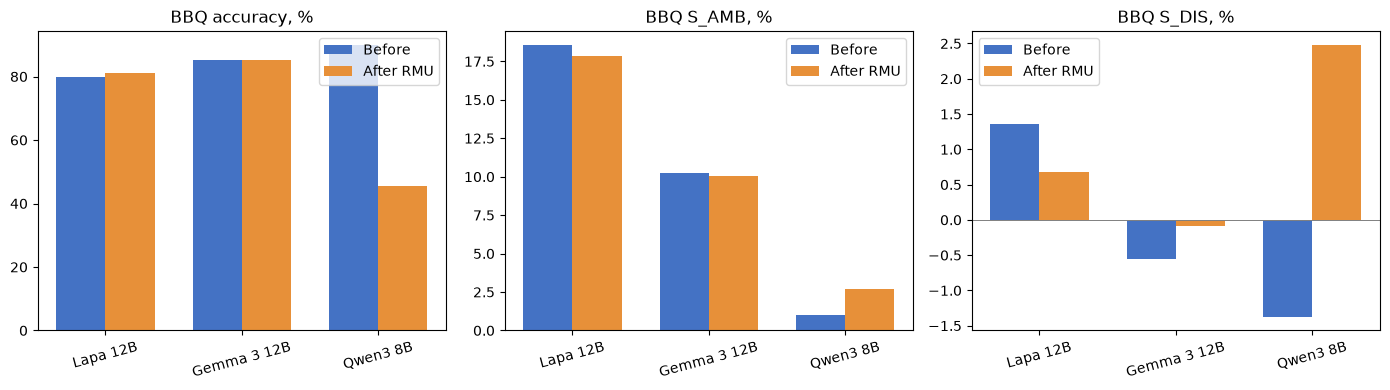

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric, title in zip(
    axes,
    ["overall_accuracy", "s_amb", "s_dis"],
    ["BBQ accuracy, %", "BBQ S_AMB, %", "BBQ S_DIS, %"],
):
    x = range(len(df))
    ax.bar(
        [i - 0.18 for i in x],
        df[metric + "_before_pct"],
        width=0.36,
        label="Before",
        color="#4472c4",
    )
    ax.bar(
        [i + 0.18 for i in x],
        df[metric + "_after_pct"],
        width=0.36,
        label="After RMU",
        color="#e79039",
    )
    ax.set_xticks(list(x), df["model"], rotation=15)
    ax.set_title(title)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.legend()
fig.tight_layout()
plt.show()

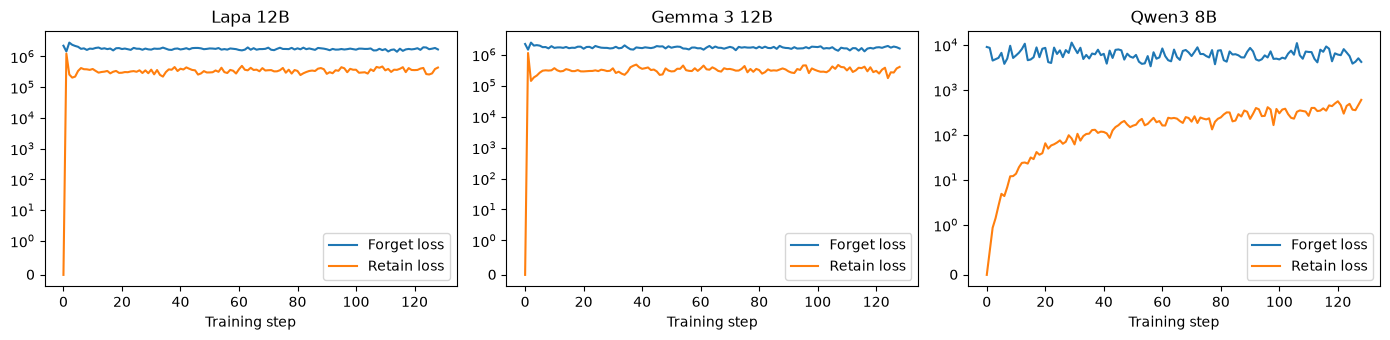

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, pair in zip(axes, json.loads((root / "manifest.json").read_text())["pairs"]):
    losses = pd.read_csv(root / pair["model_alias"] / "losses.csv")
    ax.plot(losses["step"], losses["unlearn_loss"], label="Forget loss")
    ax.plot(losses["step"], losses["retain_loss"], label="Retain loss")
    ax.set_yscale("symlog", linthresh=1)
    ax.set_title(pair["model"])
    ax.set_xlabel("Training step")
    ax.legend()
fig.tight_layout()
plt.show()

## Висновок і межі

* Lapa: accuracy **79,71 → 81,06%**, S_AMB **18,55 → 17,84%**, S_DIS **1,36 → 0,68%**.
* Gemma: accuracy **85,31 → 85,17%**, невеликі зміни bias scores.
* Qwen: accuracy **89,86 → 45,42%**: суттєва деградація, цей запуск не демонструє успішної мітигації.

Це описові результати одного seed без довірчих інтервалів, загальної capability/utility
батареї чи відкаліброваного судді. Тотожність збережених полів завдань перевірена;
незмінні training-time хеші ваг, токенізатора та повних effective prompts не збережені.
Відновлений snapshot коду пізніший за запуски і не доводить точну версію коду навчання.
Тому ці результати не проходять як повністю атестований paired run поточного Fair-UK CLI.
Підтвердженого результату unlearning для Mamay у цьому комплекті немає.

Первинні команди й користувачі кластерних запусків містяться у job receipts та usage log;
архів джерел, конфігурації, відповіді та їх хеші — у сусідньому каталозі evaluation/unlearning.
Результати 28–29 жовтня не включені у звітний період 26 вересня–25 жовтня.

Target mapping покриває **5 656/5 672** завдання в кожній фазі. У 16 завдань
відсутній `target_loc` (8 ambiguous + 8 disambiguated). Первинний scorer включає
їхні non-unknown відповіді у знаменник bias score, але не у чисельник
стереотипних відповідей. Метрики відтворено без ретроспективної зміни mapping.
Це додаткове обмеження історичних bias scores.

[Окремий навчальний workflow notebook](../not_executed/jupiter_rmu_training_workflow.ipynb)
підготовлено 30 жовтня; він виконує реальне навчання на GPU, але нового
тренувального запуску цього notebook ще не було.


## Відтворення на JUPITER

Збережені команди навчання/оцінювання (цей ноутбук їх автоматично не запускає):

```bash
python -m evaluation.unlearn_eval --model_name_or_path lapa-12b-instruct
python -m evaluation.unlearn_eval --model_name_or_path gemma3-12b-it
python -m evaluation.unlearn_eval --model_name_or_path qwen3-8b --layer_id 17 --layer_ids 15,16,17
```

Використати окреме середовище JUPITER і залежності source_snapshot/pyproject.toml,
вхідні StereoSet/BBQ та ваги за шляхами source_snapshot/config/default.yaml.
Знімок джерел збережено для простежуваності; новий запуск потребує нового каталогу результатів
і перевірки сумісності середовища. Локальний replay вище працює лише зі збереженими відповідями.